In [1]:

# MINI PROJECT: FASHION ITEM RECOGNITION

import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

# Keep experiments reproducible
np.random.seed(42)
tf.random.set_seed(42)

# 1. LOAD AND VISUALIZE DATASET

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 22s 1us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 3s 1us/step


In [2]:
names = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
         "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

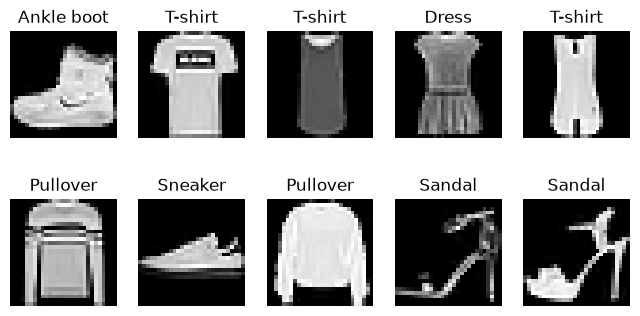

In [3]:
# Display 10 images
plt.figure(figsize=(8, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(names[y_train[i]])
    plt.axis("off")

plt.show()

In [4]:
# Normalize images
x_train = x_train / 255.0
x_test = x_test / 255.0

In [5]:
# 2. FULLY CONNECTED NEURAL NETWORK

dense_model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

dense_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Training Fully Connected Model")

dense_history = dense_model.fit(
    x_train, y_train,
    epochs=3,
    validation_split=0.1
)

dense_loss, dense_acc = dense_model.evaluate(x_test, y_test)

C:\Users\nithi\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Training Fully Connected Model
Epoch 1/3
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8188 - loss: 0.5128 - val_accuracy: 0.8528 - val_loss: 0.4079
Epoch 2/3
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8625 - loss: 0.3823 - val_accuracy: 0.8638 - val_loss: 0.3729
Epoch 3/3
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8753 - loss: 0.3412 - val_accuracy: 0.8652 - val_loss: 0.3653
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8611 - loss: 0.3966


In [6]:
# 3. BUILD CNN MODEL

x_train_cnn = x_train.reshape(-1, 28, 28, 1)
x_test_cnn = x_test.reshape(-1, 28, 28, 1)

cnn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(16, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Dense(10, activation="softmax")
])

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Training CNN Model")

cnn_history = cnn_model.fit(
    x_train_cnn, y_train,
    epochs=3,
    validation_split=0.1
)

cnn_loss, cnn_acc = cnn_model.evaluate(x_test_cnn, y_test)

Training CNN Model
Epoch 1/3
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.8241 - loss: 0.4995 - val_accuracy: 0.8648 - val_loss: 0.3634
Epoch 2/3
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8777 - loss: 0.3418 - val_accuracy: 0.8822 - val_loss: 0.3163
Epoch 3/3
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8911 - loss: 0.3042 - val_accuracy: 0.8943 - val_loss: 0.2901
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8900 - loss: 0.3054


In [7]:
# 4. COMPARE MODELS

print("\nMODEL COMPARISON")
print("Fully Connected Accuracy:", round(dense_acc * 100, 2), "%")
print("CNN Accuracy:", round(cnn_acc * 100, 2), "%")


MODEL COMPARISON
Fully Connected Accuracy: 86.11 %
CNN Accuracy: 89.0 %


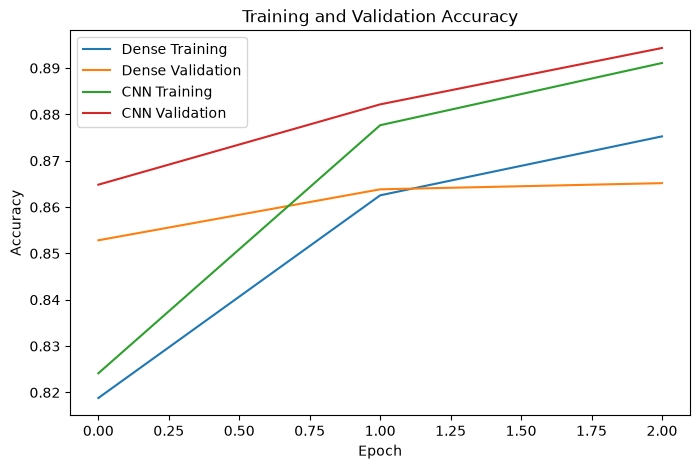

In [8]:
# Plot training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(dense_history.history["accuracy"], label="Dense Training")
plt.plot(dense_history.history["val_accuracy"], label="Dense Validation")
plt.plot(cnn_history.history["accuracy"], label="CNN Training")
plt.plot(cnn_history.history["val_accuracy"], label="CNN Validation")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

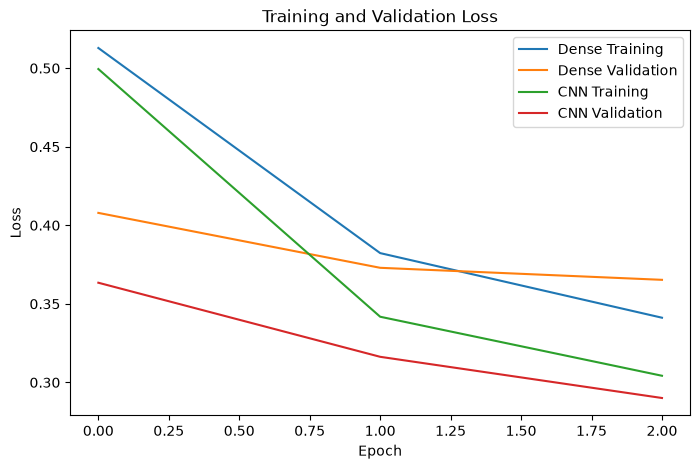

In [9]:
# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(dense_history.history["loss"], label="Dense Training")
plt.plot(dense_history.history["val_loss"], label="Dense Validation")
plt.plot(cnn_history.history["loss"], label="CNN Training")
plt.plot(cnn_history.history["val_loss"], label="CNN Validation")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

Example 1
Actual: Sneaker
Predicted: Bag
Reason: Similar clothing shapes or unclear image details.

Example 2
Actual: Ankle boot
Predicted: Sandal
Reason: Similar clothing shapes or unclear image details.

Example 3
Actual: Coat
Predicted: Pullover
Reason: Similar clothing shapes or unclear image details.

Example 4
Actual: Shirt
Predicted: T-shirt
Reason: Similar clothing shapes or unclear image details.

Example 5
Actual: Dress
Predicted: T-shirt
Reason: Similar clothing shapes or unclear image details.


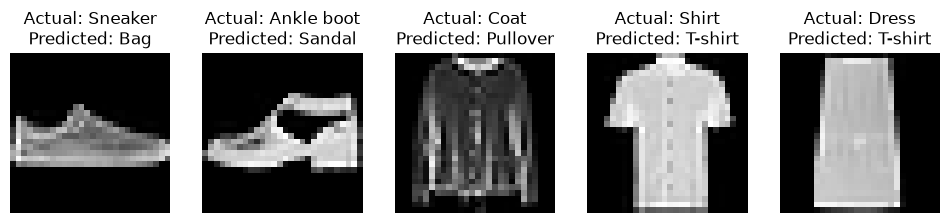

In [10]:
# 5. FIND FIVE MISCLASSIFIED IMAGES

predictions = cnn_model.predict(x_test_cnn)
predicted_labels = np.argmax(predictions, axis=1)

wrong = np.where(predicted_labels != y_test)[0]

plt.figure(figsize=(12, 5))

for i in range(5):
    index = wrong[i]

    actual = names[y_test[index]]
    predicted = names[predicted_labels[index]]

    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test[index], cmap="gray")
    plt.title("Actual: " + actual + "\nPredicted: " + predicted)
    plt.axis("off")

    print("\nExample", i + 1)
    print("Actual:", actual)
    print("Predicted:", predicted)
    print("Reason: Similar clothing shapes or unclear image details.")

plt.show()

## 6. Evaluate class-wise performance

A confusion matrix shows which clothing categories the CNN predicts correctly and which categories it tends to mix up.

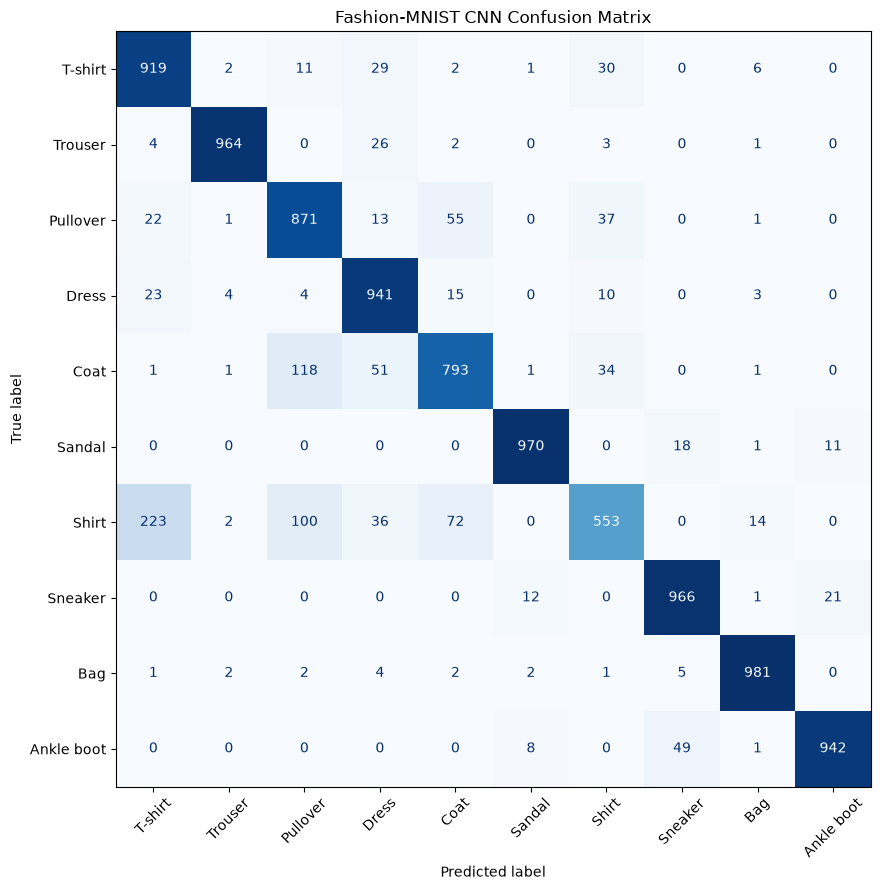

T-shirt: 91.90%
Trouser: 96.40%
Pullover: 87.10%
Dress: 94.10%
Coat: 79.30%
Sandal: 97.00%
Shirt: 55.30%
Sneaker: 96.60%
Bag: 98.10%
Ankle boot: 94.20%


In [11]:
# Calculate and display the confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, predicted_labels)
fig, ax = plt.subplots(figsize=(9, 9))
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=names)
display.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title("Fashion-MNIST CNN Confusion Matrix")
plt.tight_layout()
plt.show()

# Per-class accuracy helps identify difficult categories
class_accuracy = cm.diagonal() / cm.sum(axis=1)
for label, score in zip(names, class_accuracy):
    print(f"{label}: {score * 100:.2f}%")


### Observation
Compare the two model accuracies and inspect the confusion matrix. Categories with similar appearance (for example, shirts, pullovers and coats) may be confused more often. Use the actual values printed by your notebook when explaining the result.

In [12]:
# SAVE THE TRAINED CNN MODEL

cnn_model.save("fashion_mnist_cnn.keras")

print("\nCNN model saved successfully!")


CNN model saved successfully!
